In [1]:
import xarray as xr
from datetime import datetime, date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer
from scipy.stats import anderson_ksamp

In [2]:
ds = xr.load_dataset("target_variables/grib_files/tp_40_45.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly1 = var_hourly[:,:,:-7]

In [3]:
ds = xr.load_dataset("target_variables/grib_files/tp_46_51.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly2 = var_hourly[:,:,5:-7]

In [4]:
ds = xr.load_dataset("target_variables/grib_files/tp_52_57.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly3 = var_hourly[:,:,5:-7]

In [5]:
ds = xr.load_dataset("target_variables/grib_files/tp_58_63.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly4 = var_hourly[:,:,5:-7]

In [6]:
ds = xr.load_dataset("target_variables/grib_files/tp_64_69.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly5 = var_hourly[:,:,5:-7]

In [7]:
ds = xr.load_dataset("target_variables/grib_files/tp_70_75.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly6 = var_hourly[:,:,5:-7]

In [8]:
ds = xr.load_dataset("target_variables/grib_files/tp_76_81.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly7 = var_hourly[:,:,5:-7]

In [9]:
ds = xr.load_dataset("target_variables/grib_files/tp_82_87.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly8 = var_hourly[:,:,5:-7]

In [10]:
ds = xr.load_dataset("target_variables/grib_files/tp_88_93.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly9 = var_hourly[:,:,5:-7]

In [11]:
ds = xr.load_dataset("target_variables/grib_files/tp_94_99.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly10 = var_hourly[:,:,5:-7]

In [12]:
ds = xr.load_dataset("target_variables/grib_files/tp_00_05.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly11 = var_hourly[:,:,5:-7]

In [13]:
ds = xr.load_dataset("target_variables/grib_files/tp_06_10.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly12 = var_hourly[:,:,5:-7]

In [14]:
ds = xr.load_dataset("target_variables/grib_files/tp_11_15.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly13 = var_hourly[:,:,5:-7]

In [15]:
ds = xr.load_dataset("target_variables/grib_files/tp_16_20.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly14 = var_hourly[:,:,5:-7]

In [16]:
ds = xr.load_dataset("target_variables/grib_files/tp_21_25.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly15 = var_hourly[:,:,5:]

In [17]:
var_hourly = xr.concat([var_hourly1, var_hourly2, var_hourly3, var_hourly4, var_hourly5, var_hourly6, var_hourly7, var_hourly8, var_hourly9, 
                        var_hourly10, var_hourly11, var_hourly12, var_hourly13, var_hourly14, var_hourly15], dim='valid_time')

In [18]:
var_hourly = var_hourly.reset_coords(['time', 'step', 'hour', 'number', 'surface'], drop=True)

In [19]:
var_daily = var_hourly.groupby(var_hourly.valid_time.dt.date).sum()

In [20]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [21]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [22]:
var_daily = var_daily.sel(time=slice("1940-07", "2025-06"))
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=(month==12)|(month==1)|((month==2) & (day<29)))

### Spatial weights

In [23]:
ds_oro = xr.load_dataset("target_variables/grib_files/orography_original_res.grib", engine="cfgrib")

Ignoring index file 'target_variables/grib_files/orography_original_res.grib.5b7b6.idx' incompatible with GRIB file


In [24]:
g = 9.80665

In [25]:
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

In [26]:
lat = ds_oro.latitude
land_frac = ds_oro.lsm + ds_oro.cl
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)

In [27]:
weights = np.cos(np.deg2rad(lat))*land_frac*mount_filt
weights.name = "weights"

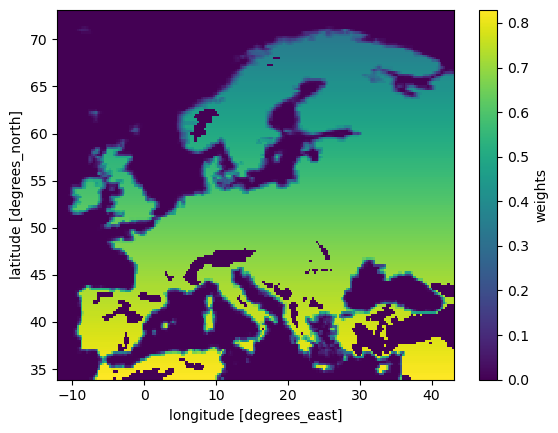

In [28]:
weights.plot()

### Time series of region means

**Northern Europe**: 4°E-42°E, 59°N-72°N  
**Western-Central Europe**: 11°W-19°E, 47°N-59°N  
**Eastern Europe**: 19°E-42°E, 47°N-59°N  
**Southwestern Europe**: 10°W-10°E, 36°N-47°N  
**Southeastern Europe**: 10°E-30°E, 35°N-47°N

In [29]:
# Choose extent of the region:

lon_min = -10
lon_max = 10
lat_max = 47
lat_min = 36

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [30]:
var_7dMean_regmean = var_daily_regmean.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean_regmean.time.dt.month
day = var_7dMean_regmean.time.dt.day
var_7dMean_regmean = var_7dMean_regmean.sel(time=~( ((month==12)&(day<4)) | ((month==2)&(day>25)) ))

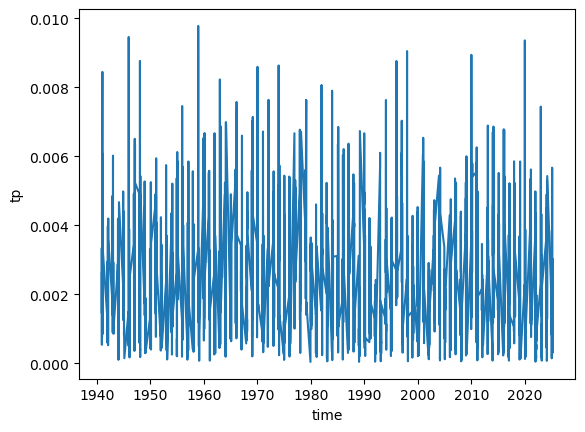

In [31]:
var_7dMean_regmean.plot()

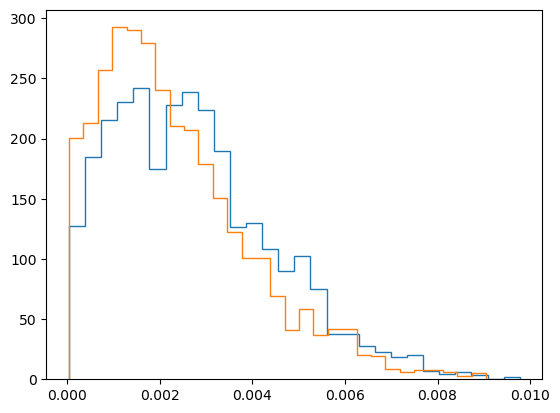

In [32]:
plt.hist(var_7dMean_regmean.sel(time=slice("1950-07", "1980-06")), bins='auto', density=True, histtype='step')
plt.hist(var_7dMean_regmean.sel(time=slice("1980-07", "2010-06")), bins='auto', density=True, histtype='step')
plt.show()

In [33]:
var_7dMean_regmean_detr_50_80 = var_7dMean_regmean.sel(time=slice("1950-07", "1980-06")) - var_7dMean_regmean.sel(time=slice("1950-07", "1980-06")).mean()
var_7dMean_regmean_detr_80_10 = var_7dMean_regmean.sel(time=slice("1980-07", "2010-06")) - var_7dMean_regmean.sel(time=slice("1980-07", "2010-06")).mean()

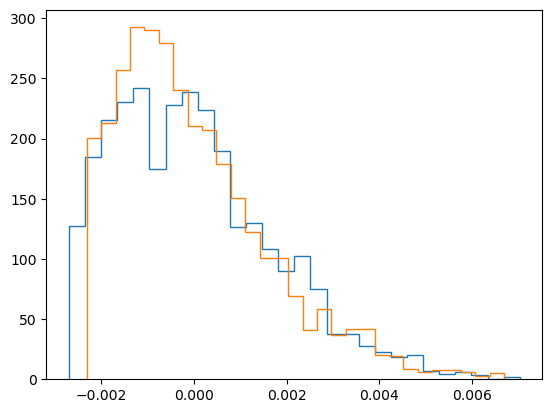

In [34]:
plt.hist(var_7dMean_regmean_detr_50_80, bins='auto', density=True, histtype='step')
plt.hist(var_7dMean_regmean_detr_80_10, bins='auto', density=True, histtype='step')
plt.show()

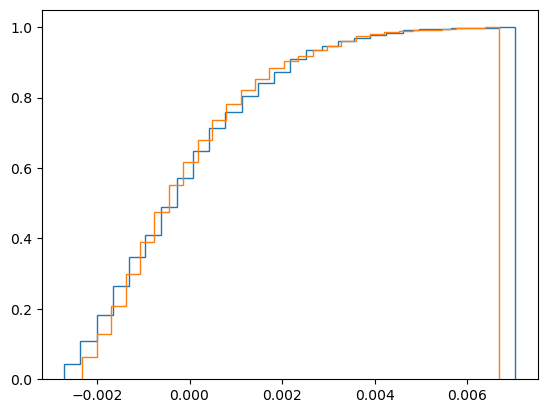

In [35]:
plt.hist(var_7dMean_regmean_detr_50_80, bins='auto', density=True, histtype='step', cumulative=True)
plt.hist(var_7dMean_regmean_detr_80_10, bins='auto', density=True, histtype='step', cumulative=True)
plt.show()

In [36]:
var_7dMean_regmean_train = var_7dMean_regmean.sel(time=slice("1950-07", "2010-06"))

bc_transformer = PowerTransformer(method="box-cox")
transformed_values = bc_transformer.fit(var_7dMean_regmean_train.values.reshape(-1, 1)).transform(var_7dMean_regmean.values.reshape(-1, 1))

In [37]:
transvar_7dMean_regmean = var_7dMean_regmean.copy()
transvar_7dMean_regmean[:] = transformed_values[:,0]

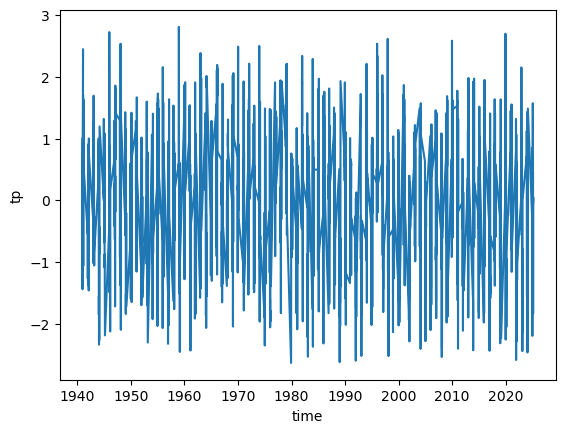

In [38]:
transvar_7dMean_regmean.plot()

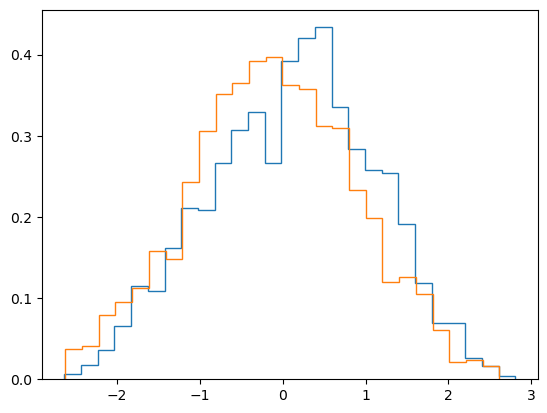

In [39]:
plt.hist(transvar_7dMean_regmean.sel(time=slice("1950-07", "1980-06")), bins='auto', density=True, histtype='step')
plt.hist(transvar_7dMean_regmean.sel(time=slice("1980-07", "2010-06")), bins='auto', density=True, histtype='step')
plt.show()

In [40]:
transvar_7dMean_regmean_detr_50_80 = transvar_7dMean_regmean.sel(time=slice("1950-07", "1980-06")) - transvar_7dMean_regmean.sel(time=slice("1950-07", "1980-06")).mean()
transvar_7dMean_regmean_detr_80_10 = transvar_7dMean_regmean.sel(time=slice("1980-07", "2010-06")) - transvar_7dMean_regmean.sel(time=slice("1980-07", "2010-06")).mean()

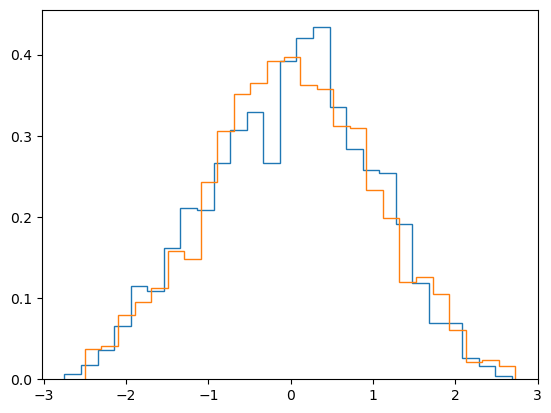

In [41]:
plt.hist(transvar_7dMean_regmean_detr_50_80, bins='auto', density=True, histtype='step')
plt.hist(transvar_7dMean_regmean_detr_80_10, bins='auto', density=True, histtype='step')
plt.show()

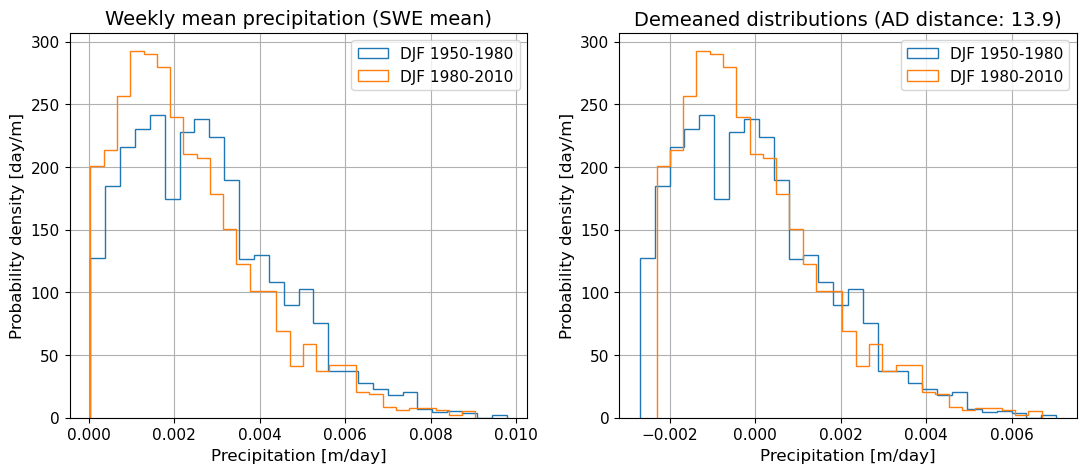

In [46]:
fig, ax = plt.subplots(1,2,figsize=(13,5))

ax[0].hist(var_7dMean_regmean.sel(time=slice("1950-07", "1980-06")), bins='auto', density=True, histtype='step', label='DJF 1950-1980')
ax[0].hist(var_7dMean_regmean.sel(time=slice("1980-07", "2010-06")), bins='auto', density=True, histtype='step', label='DJF 1980-2010')
ax[0].set_xlabel('Precipitation [m/day]',fontsize=12)
ax[0].set_ylabel('Probability density [day/m]',fontsize=12)
ax[0].set_title('Weekly mean precipitation (SWE mean)',fontsize=14)
ax[0].legend(fontsize=11)
ax[0].grid()
ax[0].tick_params(labelsize=11)

ax[1].hist(var_7dMean_regmean_detr_50_80, bins='auto', density=True, histtype='step', label='DJF 1950-1980')
ax[1].hist(var_7dMean_regmean_detr_80_10, bins='auto', density=True, histtype='step', label='DJF 1980-2010')
ax[1].set_xlabel('Precipitation [m/day]',fontsize=12)
ax[1].set_ylabel('Probability density [day/m]',fontsize=12)
ax[1].set_title('Demeaned distributions (AD distance: 13.9)',fontsize=14)
ax[1].legend(fontsize=11)
ax[1].grid()
ax[1].tick_params(labelsize=11)

plt.savefig('detrending_precip_raw.pdf', bbox_inches='tight')

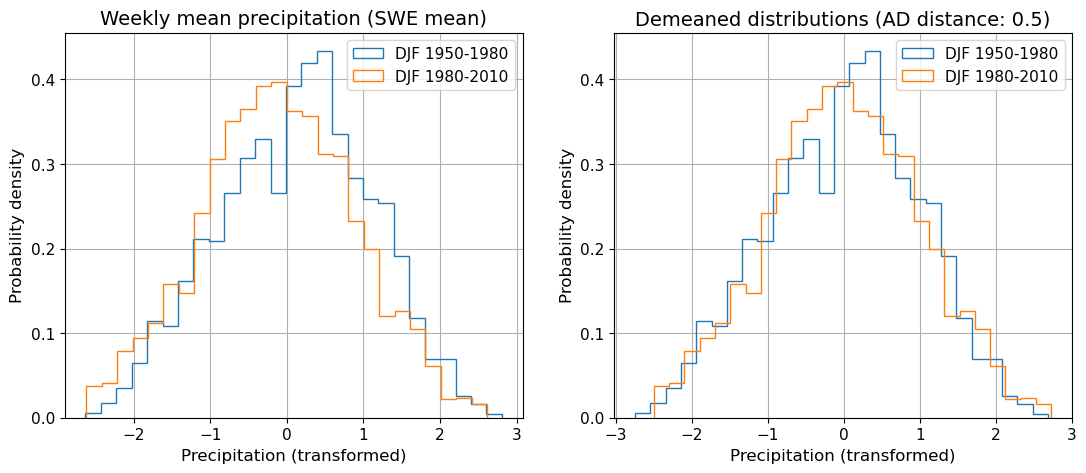

In [47]:
fig, ax = plt.subplots(1,2,figsize=(13,5))

ax[0].hist(transvar_7dMean_regmean.sel(time=slice("1950-07", "1980-06")), bins='auto', density=True, histtype='step', label='DJF 1950-1980')
ax[0].hist(transvar_7dMean_regmean.sel(time=slice("1980-07", "2010-06")), bins='auto', density=True, histtype='step', label='DJF 1980-2010')
ax[0].set_xlabel('Precipitation (transformed)',fontsize=12)
ax[0].set_ylabel('Probability density',fontsize=12)
ax[0].set_title('Weekly mean precipitation (SWE mean)',fontsize=14)
ax[0].legend(fontsize=11)
ax[0].grid()
ax[0].tick_params(labelsize=11)

ax[1].hist(transvar_7dMean_regmean_detr_50_80, bins='auto', density=True, histtype='step', label='DJF 1950-1980')
ax[1].hist(transvar_7dMean_regmean_detr_80_10, bins='auto', density=True, histtype='step', label='DJF 1980-2010')
ax[1].set_xlabel('Precipitation (transformed)',fontsize=12)
ax[1].set_ylabel('Probability density',fontsize=12)
ax[1].set_title('Demeaned distributions (AD distance: 0.5)',fontsize=14)
ax[1].legend(fontsize=11)
ax[1].grid()
ax[1].tick_params(labelsize=11)

plt.savefig('detrending_precip_trans.pdf', bbox_inches='tight')

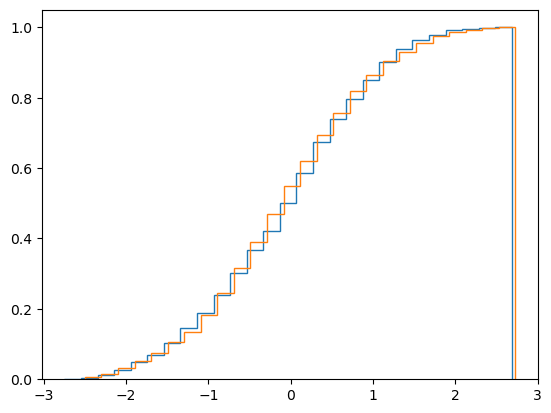

In [42]:
plt.hist(transvar_7dMean_regmean_detr_50_80, bins='auto', density=True, histtype='step', cumulative=True)
plt.hist(transvar_7dMean_regmean_detr_80_10, bins='auto', density=True, histtype='step', cumulative=True)
plt.show()

In [131]:
# NE:
print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)
print(anderson_ksamp([transvar_7dMean_regmean_detr_50_80, transvar_7dMean_regmean_detr_80_10]).statistic)

6.686159343793967
1.8644041285170936


C:\Users\lasse\AppData\Local\Temp\ipykernel_19024\3008853312.py:2: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)


In [144]:
# WCE:
print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)
print(anderson_ksamp([transvar_7dMean_regmean_detr_50_80, transvar_7dMean_regmean_detr_80_10]).statistic)

19.389154516871695
10.373476325829474


C:\Users\lasse\AppData\Local\Temp\ipykernel_19024\2583173490.py:2: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)
C:\Users\lasse\AppData\Local\Temp\ipykernel_19024\2583173490.py:3: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  print(anderson_ksamp([transvar_7dMean_regmean_detr_50_80, transvar_7dMean_regmean_detr_80_10]).statistic)


In [91]:
# EE:
print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)
print(anderson_ksamp([transvar_7dMean_regmean_detr_50_80, transvar_7dMean_regmean_detr_80_10]).statistic)

0.571149464840492
0.8540666687262185


In [43]:
# SWE:
print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)
print(anderson_ksamp([transvar_7dMean_regmean_detr_50_80, transvar_7dMean_regmean_detr_80_10]).statistic)

13.890218298633586
0.45514695212832956


C:\Users\lasse\AppData\Local\Temp\ipykernel_30528\1774685024.py:2: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)


In [105]:
# SEE:
print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)
print(anderson_ksamp([transvar_7dMean_regmean_detr_50_80, transvar_7dMean_regmean_detr_80_10]).statistic)

7.3492199451540206
7.05632603315793


C:\Users\lasse\AppData\Local\Temp\ipykernel_19024\587326632.py:2: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  print(anderson_ksamp([var_7dMean_regmean_detr_50_80, var_7dMean_regmean_detr_80_10]).statistic)
C:\Users\lasse\AppData\Local\Temp\ipykernel_19024\587326632.py:3: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  print(anderson_ksamp([transvar_7dMean_regmean_detr_50_80, transvar_7dMean_regmean_detr_80_10]).statistic)
